<div style="box-sizing:border-box;max-width:100%;margin:0 0 8px;padding:4px 0;color:inherit;line-height:1.35;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:52px!important;max-width:52px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;"><div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:8px 12px;"><span style="min-width:0;color:inherit;font-size:12px;font-weight:700;letter-spacing:0.055em;text-transform:uppercase;"><a href="https://thetahat.ru/courses/ysda-group" style="color:inherit;text-decoration:none;">Школа анализа данных</a>&nbsp;·&nbsp;Машинное обучение</span></div></div>

<h2><span style="display:block;box-sizing:border-box;max-width:100%;padding:16px 22px 17px;border-radius:14px;background:linear-gradient(135deg,#D4470E 0%,#C7324E 50%,#B316B8 100%);color:#FFFFFF;line-height:1.15;font-weight:500;">Интервальные оценки</span></h2>

In [1]:
from functools import partial
from typing import Callable, List, Literal, Optional, Sequence, Tuple, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sps
import seaborn as sns
from matplotlib.lines import Line2D
from sklearn.datasets import load_wine
from sklearn.linear_model import LinearRegression
from tqdm import tqdm

from confidence_intervals_tools import (
    plot_point_estimates_vs_truth,
    plot_regression_with_residuals,
    plot_parameter_interval,
    plot_intervals,
    plot_feature_intervals,
    draw_confidence_interval
)

sns.set(style="whitegrid", palette="Set2", font_scale=1.3)
rng = np.random.default_rng(42)

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1</span> <span style="color:inherit;">Интуиция точечных оценок</span>

Ранее мы рассматривали исключительно точечные оценки параметров. Каждому неизвестному параметру сопоставлялось одно число. В задаче регрессии модель возвращала единственное численное значение в качестве предсказания. Однако возникает естественный вопрос: **насколько такие предсказания соответствуют истинному значению?**

Следует помнить, что точечная оценка является случайной величиной — она зависит от конкретной выборки данных и потому не обязана в точности совпадать с истинным параметром. Более того, при изменении данных она может заметно варьироваться.

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.1</span> <span style="color:inherit;">Оценки параметров</span>

Для наглядности посмотрим на разброс получаемых оценок относительно истинного значения параметра $\theta$.

Сгенерируем $M$ независимых выборок размера $n$ из распределения $\mathcal{N}(\theta,\sigma^2)$ и для каждой находим оценку параметра $\theta$ как выборочное среднее:

$$ X_{ji} \sim \mathcal{N}(\theta,\sigma^2), \qquad \widehat{\theta_j}=\overline{X_j}=\frac{1}{n}\sum_{i=1}^{n}X_{ji} $$

In [2]:
def simulate_means(
    theta: float = 0.0, sigma: float = 1.0, sample_size: int = 20, num_replications: int = 5
) -> np.ndarray:
    """
    Симулирует и возвращает выборочные средние из нормального распределения.

    Args:
        theta: Истинное среднее нормального распределения (мат. ожидание).
        sigma: Стандартное отклонение нормального распределения.
        sample_size: Размер каждой генерируемой выборки.
        num_replications: Количество симуляций (сколько выборок сгенерировать).

    Returns:
        Массив, содержащий выборочные средние для каждой симуляции.
    """
    # Генерируем матрицу данных: строки - эксперименты, столбцы - наблюдения
    samples = rng.normal(theta, sigma, size=(num_replications, sample_size))

    # Вычисляем среднее по каждому эксперименту
    return samples.mean(axis=1)

Генерируем 6 выборочных средних из выборок по 20 наблюдений и посмотрим на их отклонения от истины

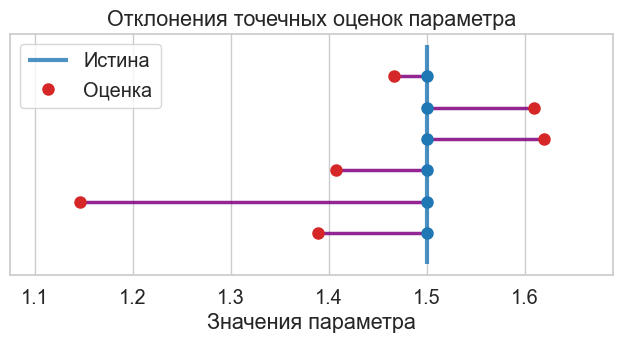

In [3]:
# Истинное значение параметра
theta_true = 1.5

sample_means = simulate_means(theta=theta_true, sigma=1.0, sample_size=20, num_replications=6)

plot_point_estimates_vs_truth(
    point_estimates=sample_means, true_parameter=theta_true, margin=0.15, figsize=(6.5, 2.2)
)

#### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.2</span> <span style="color:inherit;">Отклонения в регрессии</span>

Аналогичная идея применима и в задаче регрессии: модель строит линию регрессии $\widehat{y}(x)$, однако реальные наблюдения $Y_i$ наверняка отклоняются от этого предсказания. Фактически, ни одно наблюдение $Y_i$ не попадает точно на предсказанную линию, что отражает наличие случайной ошибки в данных.

Для наглядности продемонстрируем вертикальные отрезки — «ошибки предсказания» — соединяющие фактические наблюдения $(x_i, Y_i)$ с соответствующими точками на линии регрессии $(x_i, \widehat{y}(x_i))$. Эти отрезки визуализируют величину остатка $e_i = Y_i - \widehat{y}(x_i)$ для каждого наблюдения.

In [4]:
def generate_data(
    num_samples: int = 1000, intercept: float = 2.0, slope: float = 0.6
) -> tuple[np.ndarray, np.ndarray]:
    """
    Генерирует синтетические данные.
    """
    feature_x = np.linspace(0, 10, num_samples)
    error_std = 0.3 + 0.1 * feature_x
    noise = rng.normal(0, error_std, size=num_samples)
    target_y = intercept + slope * feature_x + noise
    return feature_x, target_y

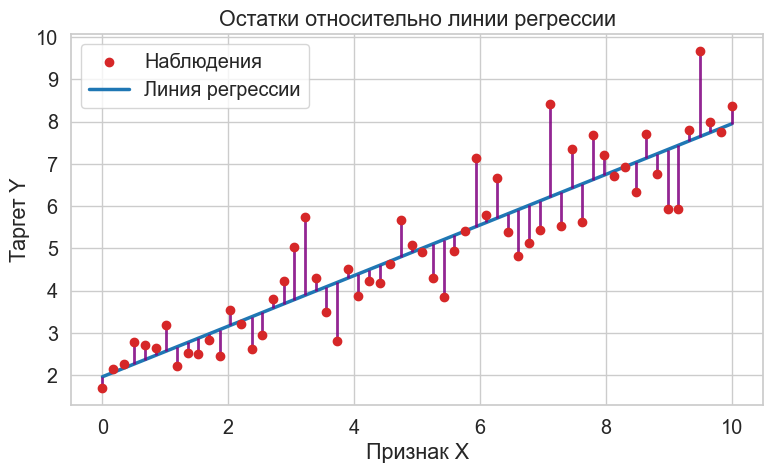

In [5]:
feature, target = generate_data(num_samples=60)
plot_regression_with_residuals(feature, target)

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">1.3</span> <span style="color:inherit;">Интуиция по MSE</span>

Мы убедились, что модель регрессии не может точно воспроизвести все наблюдения.  Возникает закономерный вопрос: **как количественно оценить типичную величину ошибки предсказания?** Иными словами, можно ли определить диапазон, в котором с высокой вероятностью находятся реальные значения?

Для оценки ошибки моделей мы ранее использовать **MSE**:
$$
\text{MSE} = \frac{1}{n}\sum_{i=1}^n \left(Y_i - \widehat{Y}_i\right)^2
$$

В качестве первой попытки оценить неопределенность предсказаний можно построить полосу неопределённости вокруг линии регрессии:
$$
\widehat{y}(x) \pm \sqrt{\text{MSE(train)}}
$$

Однако возникает важный вопрос: насколько такая полоса соответствует реальности? Отражает ли она истинную неопределённость и покрывает достаточную долю наблюдений?

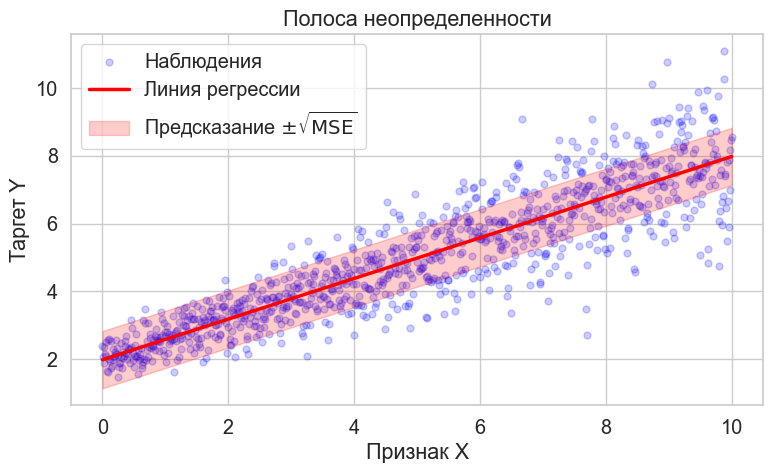

In [6]:
feature, target = generate_data(num_samples=1000)

model = LinearRegression().fit(feature.reshape(-1, 1), target)
predicted = model.predict(feature.reshape(-1, 1))
rmse = np.sqrt(np.mean((target - predicted) ** 2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(feature, target, s=25, color="blue", alpha=0.2, label="Наблюдения")
ax.plot(feature, predicted, color="red", lw=2.5, label="Линия регрессии")
ax.fill_between(
    feature,
    predicted - rmse,
    predicted + rmse,
    color="red",
    alpha=0.2,
    label=r"Предсказание $\pm \sqrt{\mathrm{MSE}}$",
)
ax.set_xlabel("Признак X")
ax.set_ylabel("Таргет Y")
ax.set_title("Полоса неопределенности")
ax.legend()
plt.tight_layout()
plt.show()

Полоса $ \widehat{y} \pm \sqrt{\text{MSE(train)}}$ имеет **одинаковую ширину** для всех $x$. Однако на графике точки разбросаны по-разному — разброс увеличивается с ростом $x$. Это означает, что MSE усредняет ошибки и не отражает реальную неопределённость в каждом регионе.  


Чтобы учитывать её корректно, нужны интервалы, зависящие от $x$.



### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">2</span> <span style="color:inherit;">Доверительные интервалы</span>

Будем сопоставлять точечную оценку с диапазоном значений, который с заданной вероятностью **накрывает** истинный параметр $\theta$.

Так рождается концепция **доверительного интервала**:
$$
\theta \in \bigg(\,\widehat{\theta} - \text{погрешность},\ \widehat{\theta} + \text{погрешность}\,\bigg)
$$

Визуализируем эту идею: покажем единичную оценку $\widehat{\theta}$ с соответствующим доверительным интервалом и отметим истинное значение параметра $\theta$.

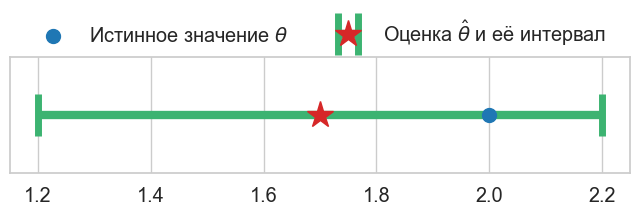

In [7]:
plot_parameter_interval(theta_true=2.0, theta_hat=1.7, delta=0.5)

Интервал построен **вокруг оценки** $\widehat{\theta}$ и накрывает истинное значение $\theta$. При многократном повторении эксперимента, интервалы будут разные. Но примерно в 95 % случаев (для уровня доверия 0.95) они будут **накрывать истинное значение параметра**.  

Это и есть смысл «доверительного уровня» — не вероятность для одной конкретной точки, а свойство процедуры в целом.

Иначе говоря смысл доверительного интервала следующий. **При многократном повторении эксперимента доверительный интервал накрывает истинное значение параметра в 95% случаев.**


Проиллюстрируем это следующим образом:
* сгенерируем большое число выборок из искомого распределения $\mathcal{N}(\theta, \sigma^2)$,
* построим для каждой 95% доверительный интервал $\alpha=0.95$,
* посмотрим, сколько из них пересекает истинное значение параметра.

---

Исследование проведем для интервалов Вальда в модели $\mathcal{N}(\theta, \sigma^2)$. Вспомним формулу с лекции.
 * асимтотический доверительный интервал Вальда
$$\bigg(\overline{X}-\frac{S}{\sqrt{n}}z_{(1+\alpha)/2},\ \overline{X}+\frac{S}{\sqrt{n}}z_{(1+\alpha)/2}\bigg)$$

Обозначения:
* $\overline{X} = \frac{1}{n}\sum\limits_{i=1}^n X_i$ &mdash; выборочное среднее;
* $S^2 = \frac{1}{n}\sum\limits_{i=1}^n \left( X_i - \overline{X} \right)^2$ &mdash; выборочная дисперсия;
* $z_{\alpha}$ &mdash; $\alpha$-квантиль распределения $\mathcal{N}(0, 1)$;

*Опцию `interval_type='predictive'` в функции разберем далее.*

In [8]:
def calculate_interval(
    data: np.ndarray,
    estimate_type: str = "wald",
    interval_type: str = "confidence",
    alpha: float = 0.95,
) -> tuple[float, float, float]:
    """
    Рассчитывает доверительный или предсказательный интервал для среднего.

    Args:
        data: Массив наблюдений (выборка).
            - 1D array: одна выборка.
            - 2D array: множество выборок, где каждая строка - отдельная выборка.
        estimate_type: Способ построения, 'student' (по умолчанию) или 'wald'.
        interval_type: Тип интервала, 'confidence' (по умолчанию) или 'predictive'.
        alpha: Уровень доверия/предсказания (например, 0.95 для 95%).

    Returns:
        Cреднее, нижняя граница интервала, верхняя граница интервала.
    """

    data = np.array(data)

    # Если на входе 1D массив
    is_1d = data.ndim == 1
    if is_1d:
        data = data.reshape(1, -1)

    if data.ndim != 2:
        raise ValueError("Входной массив `data` должен быть 1D или 2D.")

    num_experiments, sample_size = data.shape
    if sample_size < 2:
        raise ValueError("Требуется как минимум 2 наблюдения.")

    ddof = int(estimate_type == "student")  # поправка в случае интервала Стьюдента
    means = np.mean(data, axis=1)  # среднее
    stds = np.std(data, axis=1, ddof=ddof)  # стандартное отклонение, деление на n-ddof
    t_value = sps.t.ppf((1 + alpha) / 2, df=sample_size - 1)  # Квантиль

    # Квантиль
    if estimate_type == "student":
        quantile = sps.t.ppf((1 + alpha) / 2, df=sample_size - 1)
    elif estimate_type == "wald":
        quantile = sps.norm.ppf((1 + alpha) / 2)
    else:
        raise ValueError("Параметр `estimate_type` должен быть 'student' или 'wald'.")

    if interval_type == "confidence":
        margin_of_error = quantile * stds / np.sqrt(sample_size)
    elif interval_type == "predictive":
        margin_of_error = quantile * stds * np.sqrt(1 + 1 / sample_size)
    else:
        raise ValueError("Параметр `interval_type` должен быть 'confidence' или 'predictive'.")

    lower_bounds = means - margin_of_error
    upper_bounds = means + margin_of_error

    if is_1d:
        # Если на входе был 1D массив
        return means[0], lower_bounds[0], upper_bounds[0]
    else:
        return means, lower_bounds, upper_bounds

Для наглядности сгенерируем ровно 100 выборок и посчитаем для каждой из них доверительный интервал

In [9]:
num_experiments = 100
sample_size = 30
alpha = 0.95
true_theta = 0.0  # истинное среднее

# Генерируем все выборки сразу
samples = rng.normal(loc=true_theta, scale=1, size=(num_experiments, sample_size))

# Среднее для каждой выборки
sample_means = samples.mean(axis=-1)

# Доверительные интервалы для каждой выборки
_, lower_bounds, upper_bounds = calculate_interval(samples, alpha=alpha)

Найдем долю $\gamma$ доверительных интервалов, которые покрывают истинное значение параметра $\theta$. Для уровня доверия $\alpha=0.95$ ожидаемая доля покрытия составляет $95\%$.

Оценим долю покрытия по формуле:

$$
\widehat{\gamma}=\frac{1}{M}\sum_{i=1}^{M}\mathbf{I}\{L_i\leq\theta\leq U_i\},
$$

где $M$ — число экспериментов, $L_i$ и $U_i$ — нижняя и верхняя границы $i$-го доверительного интервала.

In [10]:
is_covered = (lower_bounds <= true_theta) & (true_theta <= upper_bounds)
is_covered.mean()

np.float64(0.91)

Наконец, визуализируем все эти интервалы. Зелеными выделены те **реализации**, что покрыли истинное значение параметра, красные - нет.

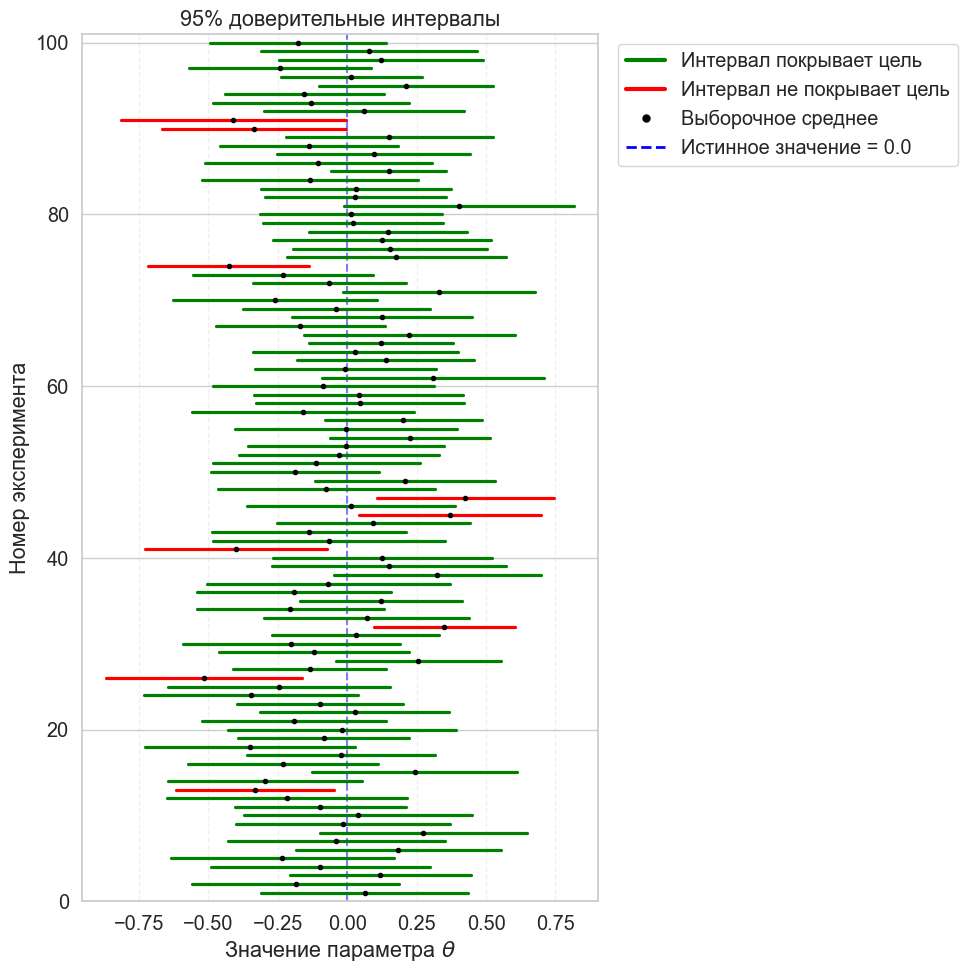

In [11]:
plot_intervals(
    num_experiments=num_experiments,
    lower_bounds=lower_bounds,
    upper_bounds=upper_bounds,
    sample_means=sample_means,
    target=true_theta,
    title=f"{int(alpha*100)}% доверительные интервалы",
)

Доверительный интервал необходимо интерпретировать как случайный объект, который при многократном повторении эксперимента в $\alpha \cdot 100\%$ случаев накрывает истинное значение $\theta$. В одной конкретной реализации истинное значение либо лежит, либо нет.

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">3</span> <span style="color:inherit;">Предсказательные интервалы</span>

Ранее мы рассматривали доверительные интервалы для параметров — они характеризуют точность оценки неизвестного, но **фиксированного** параметра. Для таких интервалов мы требовали, чтобы при многократном повторении эксперимента они накрывали истинное значение параметра в заданной доле случаев (например, 95%). Важно еще раз подчеркнуть: параметр является **неслучайной величиной**.

На практике в некоторых задачах возникает необходимость строить интервалы для **будущих наблюдений**. Речь идет не только об оценке среднего значения, но и о прогнозе диапазона, в котором с высокой вероятностью окажется следующее наблюдение. Такие интервалы называются **предсказательными**. Единственное их отличие от доверительных заключается в том, что мы оцениваем **случайную величину** (новое наблюдение), а не фиксированный параметр.

**Примеры**

- *Точечная оценка*: "Путь из дома в аэропорт занимает в среднем 30 минут"
- *Доверительный интервал*: "Среднее время пути составляет от 29 до 31 минуты" — отражает неопределённость в оценке *среднего*
- *Предсказательный интервал*: "Конкретная поездка займёт от 27 до 33 минут" — прогнозирует диапазон для *отдельного наблюдения*. Здесь тем самым мы говорим "скорее всего реальное время поездки будет не меньше 27 минут и не больше 33 минут".

Не лишнее ли это понятие? Можем ли мы использовать обычные доверительные интервалы в качестве предсказательных?

Сгенерируем для предыдущего эксперимента тестовый набор точек &mdash; по одной точке для каждой выборки.

In [12]:
# Тестовые точки для каждой выборки
test_samples = rng.normal(loc=true_theta, scale=1, size=num_experiments)

Посмотрим, сколько интервалов из 100 смогли покрыть эти тестовые точки

In [13]:
is_covered = (lower_bounds <= test_samples) & (test_samples <= upper_bounds)
is_covered.mean()

np.float64(0.25)

Да, здесь все плохо. Давайте посмотрим это на графике

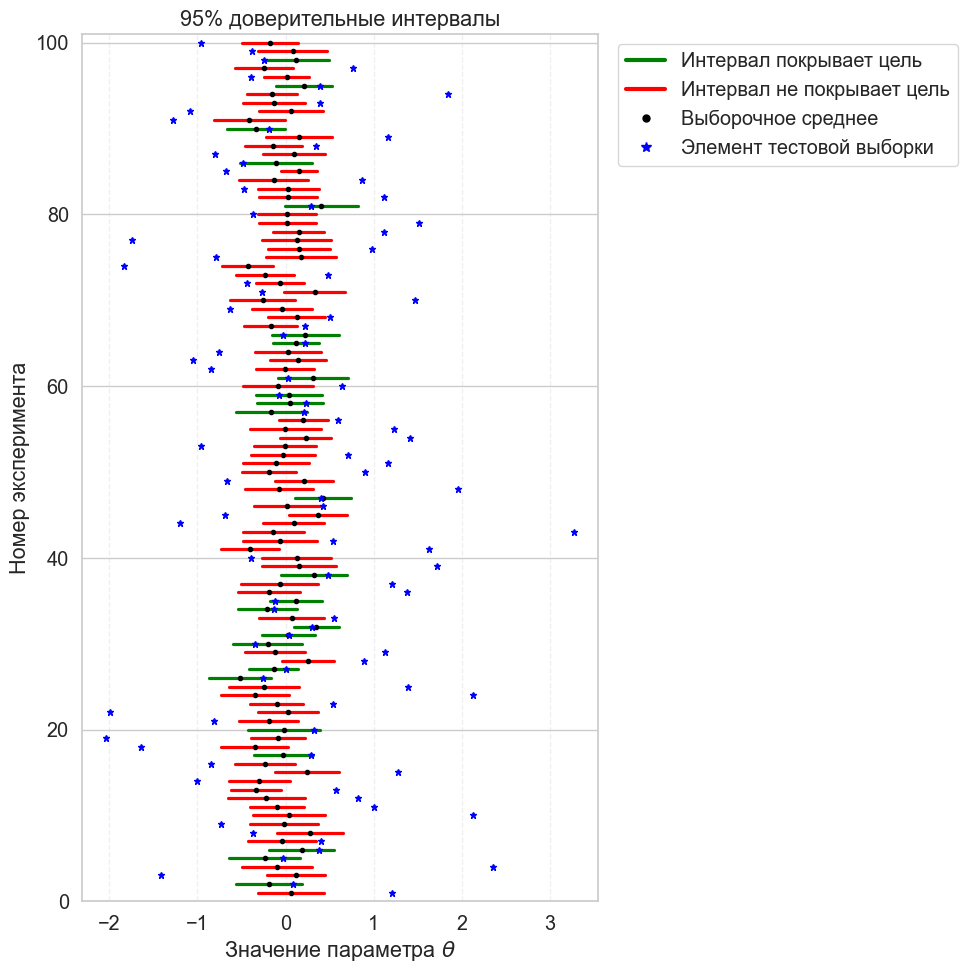

In [14]:
plot_intervals(
    num_experiments=num_experiments,
    lower_bounds=lower_bounds,
    upper_bounds=upper_bounds,
    sample_means=sample_means,
    target=test_samples,
    title=f"{int(alpha*100)}% доверительные интервалы",
)

**Способ построения предсказательных интервалов**

Предположим, что $\theta$ &mdash; параметр сдвига, то есть наблюдения получаются по правилу
$$X_i = \theta + \varepsilon_i,$$
где $\varepsilon_1, ..., \varepsilon_n$ &mdash; независимые одинаково распределенные случайные величины, которые также не зависят от $\theta$.

Тогда если мы оцениваем параметр $\theta$ оценкой $\widehat{\theta}$, то можно ожидать новое наблюдение в виде
$$\widehat{X}_{new} = \widehat{\theta} + \varepsilon_{new}.$$
Поскольку шумы независимы, получаем 
$$\mathsf{D} \widehat{X}_{new} = \mathsf{D}\widehat{\theta} + \mathsf{D}\varepsilon_{new}.$$

Например, если $\mathsf{D}\varepsilon=\sigma^2$ и $\widehat{\theta} = \overline{X}$, то
$$\mathsf{D} \widehat{X}_{new} = \frac{\sigma^2}{n} + \sigma^2 = \sigma^2 \left( \frac{1}{n} + 1 \right).$$

Тем самым в модели $\mathcal{N}(\theta, \sigma^2)$ предсказательные интервалы имеют следующий вид:
$$\left( \overline{X} \: \pm \: z_{n-1} S \sqrt{\frac{1}{n} + 1} \right)$$


Предсказательные интервалы всегда шире доверительных, поскольку они учитывают **два источника неопределённости**:
1. Ошибку оценки параметра аналогично доверительным интервалам
2. Индивидуальную случайность нового наблюдения

Это делает предсказательные интервалы полезными на практике, где важно оценивать не только средние тенденции, но и возможный разброс конкретных значений.

---

Построим предсказательные интервалы и посмотрим на их покрытие тестовых семплов

In [15]:
_, lower_bounds, upper_bounds = calculate_interval(samples, interval_type="predictive", alpha=alpha)

is_covered = (lower_bounds <= test_samples) & (test_samples <= upper_bounds)
is_covered.mean()

np.float64(0.93)

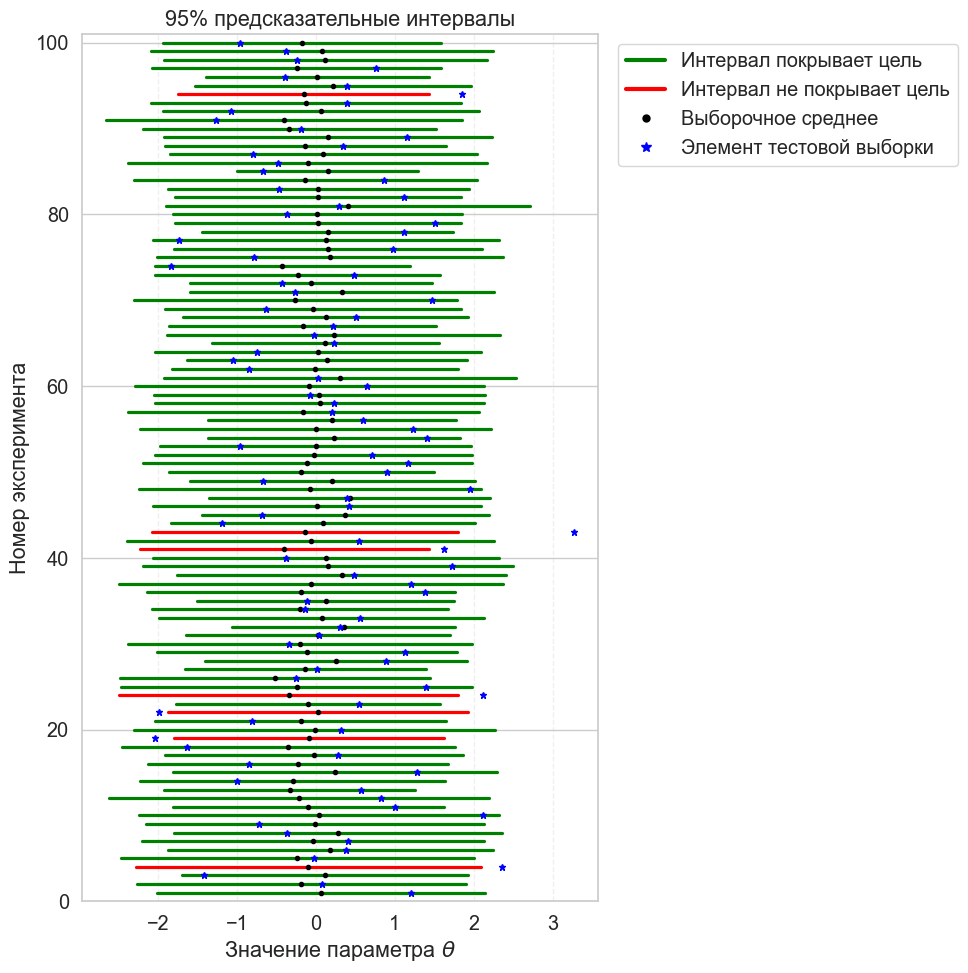

In [16]:
plot_intervals(
    num_experiments=num_experiments,
    lower_bounds=lower_bounds,
    upper_bounds=upper_bounds,
    sample_means=sample_means,
    target=test_samples,
    title=f"{int(alpha*100)}% предсказательные интервалы",
)

На графике мы можем заметить, что интервалы действительно стали шире. Кроме того, они теперь покрывают тестовые точки почти во всех случаях.

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">4</span> <span style="color:inherit;">Исследование типов вина</span>

Теперь применим доверительные интервалы на реальных данных. Возьмём **Wine dataset** из библиотеки `sklearn` — классический набор данных для задач классификации и анализа.

Набор данных содержит химический анализ 178 итальянских вин из одного региона трех различных сортов.

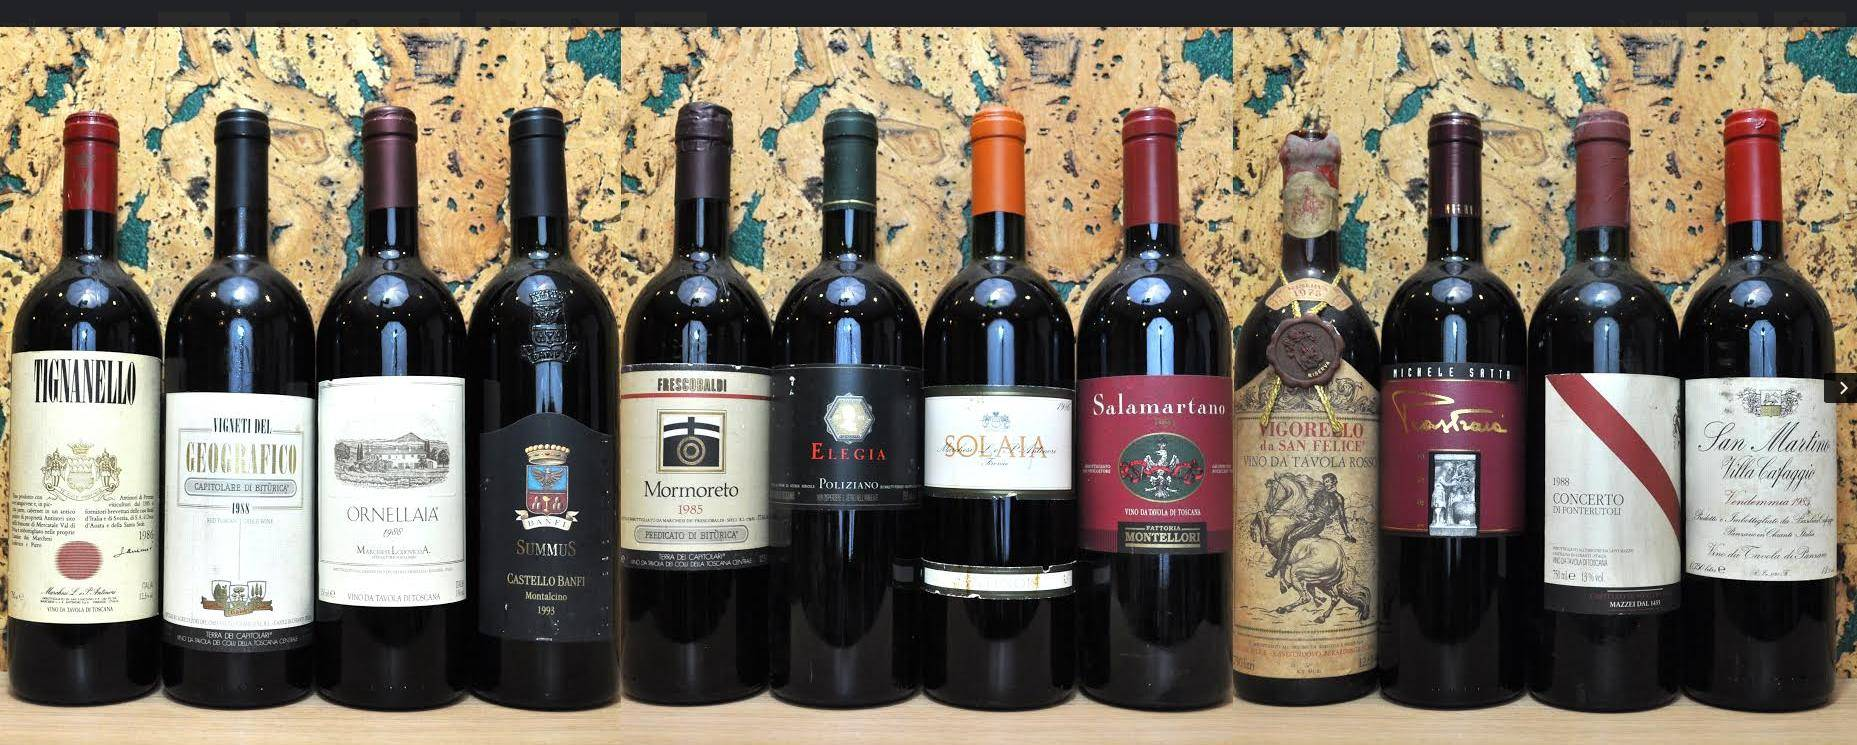

**Признаки:**

* `alcohol` — содержание алкоголя в процентах
* `malic_acid` — содержание яблочной кислоты
* `ash` — содержание золы
* `alcalinity_of_ash` — щёлочность золы
* `magnesium` — содержание магния
* `total_phenols` — общее содержание фенолов
* `flavanoids` — содержание флавоноидов
* `nonflavanoid_phenols` — содержание нефлавоноидных фенолов
* `proanthocyanins` — содержание проантоцианинов
* `color_intensity` — интенсивность цвета
* `hue` — оттенок
* `od280/od315_of_diluted_wines` — оптическая плотность разбавленных вин
* `proline` — содержание пролина

**Таргет:**
* `class` — сорт вина (0, 1, 2)


Загрузим данные и рассмотрим некоторые признаки

In [17]:
data = load_wine(as_frame=True)
df = data.frame.copy()

df.rename(columns={"target": "class"}, inplace=True)
classes = df["class"].unique()
features = ["alcohol", "malic_acid", "color_intensity"]

df.head(5)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Построим интервалы для среднего значения признаков для каждого класса. 

In [18]:
records = []
for feature in features:
    for c in classes:
        subset = df.loc[df["class"] == c, feature]
        mean, left, right = calculate_interval(subset)
        records.append((feature, c, mean, left, right))

intervals = pd.DataFrame(records, columns=["feature", "class", "mean", "left", "right"])
intervals.head()

,feature,class,mean,left,right
0,alcohol,0,13.744746,13.627831,13.861661
1,alcohol,1,12.278732,12.154484,12.402981
2,alcohol,2,13.153750,13.005317,13.302183
3,malic_acid,0,2.010678,1.836479,2.184877
4,malic_acid,1,1.932676,1.698119,2.167233


Нарисуем эти интервалы на графике

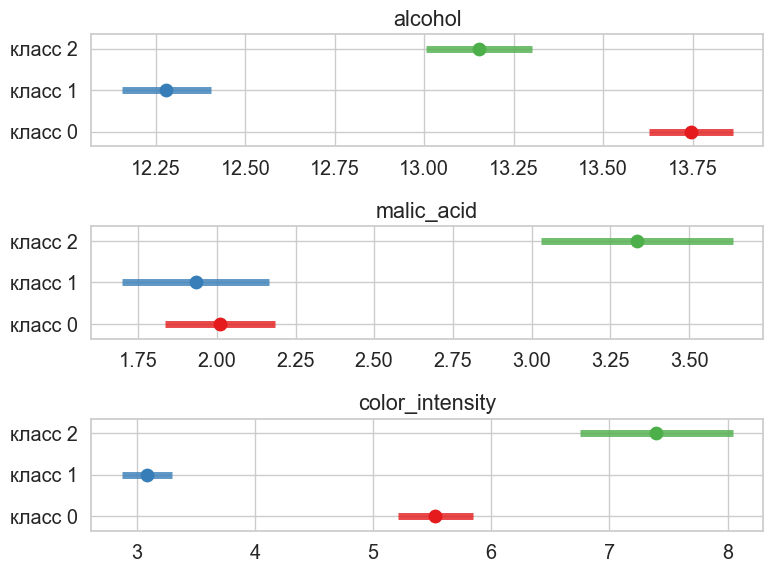

In [19]:
plot_feature_intervals(intervals, features_to_show=features)

По графикам можем сделать следующие выводы
- Для некоторых признаков (например, `alcohol`) интервалы классов почти не пересекаются, значит мы с уверенностью можем сказать, что средние значения этих типов вина отличаются.
- Для других (например, `malic_acid`) интервалы пересекаются сильно. В данном случае мы не можем сказать о том, что вина классов 0 и 1 в среднем отличаются по `malic_acid`.


Теперь посмотрим, как будут выглядеть предсказательные интервалы.

In [20]:
records = []
for feature in features:
    for c in classes:
        subset = df.loc[df["class"] == c, feature]
        mean, left, right = calculate_interval(subset, interval_type="predictive")
        records.append((feature, c, mean, left, right))

intervals = pd.DataFrame(records, columns=["feature", "class", "mean", "left", "right"])
intervals.head()

,feature,class,mean,left,right
0,alcohol,0,13.744746,12.839127,14.650365
1,alcohol,1,12.278732,11.224446,13.333018
2,alcohol,2,13.153750,12.114722,14.192778
3,malic_acid,0,2.010678,0.661341,3.360015
4,malic_acid,1,1.932676,-0.057605,3.922957


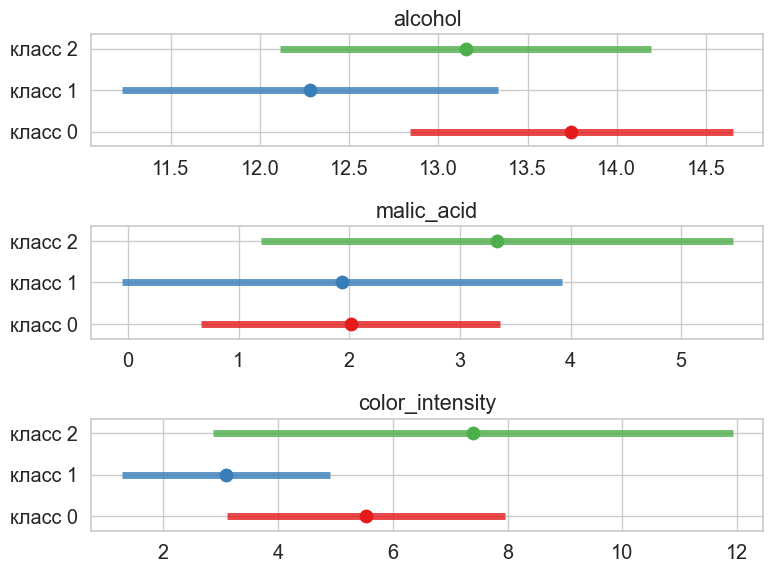

In [21]:
plot_feature_intervals(intervals, features_to_show=features)

По этим графикам видно, что интервалы стали сильно шире, и теперь уже для всех трех типов вина по всем рассмотренным признакам интервалы пересекаются. 

### <span style="display:inline-block;padding:2px 8px;border-radius:999px;background:linear-gradient(135deg, #C7480B 0%, #B52D59 54%, #A617B3 100%);color:#FFFFFF;font-size:0.78em;vertical-align:0.08em;">5</span> <span style="color:inherit;">Сравнение интервалов в зависимости от размера выборки</span>

Кроме асимтотического доверительного интервала Вальда рассмотрим точный интервал, основанный на распределении Стьюдента.

Формулы :

 * асимтотический доверительный интервал Вальда
$$\bigg(\overline{X}-\frac{S}{\sqrt{n}}z_{(1+\alpha)/2},\ \overline{X}+\frac{S}{\sqrt{n}}z_{(1+\alpha)/2}\bigg)$$
 * точный неасимптотический доверительный интервал Стьюдента
$$\bigg(\overline{X} - \frac{S}{\sqrt{n-1}}T_{n-1, (1+\alpha)/2},\ \overline{X} + \frac{S}{\sqrt{n-1}}T_{n-1, (1+\alpha)/2}\bigg)$$

Обозначения:
* $\overline{X} = \frac{1}{n}\sum\limits_{i=1}^n X_i$ &mdash; выборочное среднее;
* $S^2 = \frac{1}{n}\sum\limits_{i=1}^n \left( X_i - \overline{X} \right)^2$ &mdash; выборочная дисперсия;
* $z_{\alpha}$ &mdash; $\alpha$-квантиль распределения $\mathcal{N}(0, 1)$;
* $T_{n-1, (1+\alpha)/2}$ &mdash; $\alpha$-квантиль распределения Стюдента $T_{n-1}$.

Проведём сравнение доверительных интервалов Стьюдента и Вальда, исследуя их поведение при различных размерах выборки. 

**Методика эксперимента:**
- Для каждого размера выборки $n$ от 2 до $N$ построим оба типа интервалов
- Визуализируем на графике изменение границ интервалов по мере роста $n$
- Повторим эксперимент многократно и оценим долю покрытия — вероятность, с которой интервал накрывает истинное значение параметра. Этот этап подробнее разберем далее.

Такой подход позволит наглядно увидеть:
- Как интервалы стабилизируются с ростом выборки
- В каких случаях какой из типов интервалов предпочтительнее
- Насколько асимптотически корректен интервал Вальда для больших выборок

---

Напишем функции для построения интервалов для всех $n$ от 2 до $N$ и для визуализации полученного набора интервалов.

In [22]:
def calculate_sequential_intervals(
    sample: np.ndarray, interval_calculator: Callable, alpha: float
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Последовательно рассчитывает интервалы для нарастающих срезов выборки.

    Args:
        sample: Входная выборка.
            - 1D array: одна выборка.
            - 2D array: множество выборок, где каждая строка - отдельная выборка.
        interval_calculator: Функция для расчета интервала.
        alpha: Уровень доверия.

    Returns:
        Кортеж из трех массивов: (нижние границы, верхние границы, оценки).
    """
    # Запоминаем, был ли вход 1D
    is_1d = sample.ndim == 1
    data = np.atleast_2d(sample)

    num_experiments, sample_size = data.shape
    lower_bounds = np.full((num_experiments, sample_size), np.nan)
    upper_bounds = np.full((num_experiments, sample_size), np.nan)
    estimates = np.full((num_experiments, sample_size), np.nan)

    # Расчет начинается с выборки размером 2 (индекс i=1)
    for i in range(1, sample_size):
        current_slice = data[:, : i + 1]
        estimate, lower, upper = interval_calculator(current_slice, alpha=alpha)
        lower_bounds[:, i] = lower
        upper_bounds[:, i] = upper
        estimates[:, i] = estimate

    if is_1d:
        # Если на входе был 1D массив
        return lower_bounds.squeeze(), upper_bounds.squeeze(), estimates.squeeze()
    else:
        return lower_bounds, upper_bounds, estimates

Построим интервалы для подвыборок размера $n$ от 2 до $N=50$

In [23]:
max_sample_size = 50
sample = np.random.normal(size=max_sample_size)  # выборка
alpha = 0.95  # уровень доверия

left_wald, right_wald, mean = calculate_sequential_intervals(
    sample,
    partial(calculate_interval, estimate_type="wald"),
    alpha=alpha,
)

left_student, right_student, mean = calculate_sequential_intervals(
    sample,
    partial(calculate_interval, estimate_type="student"),
    alpha=alpha,
)

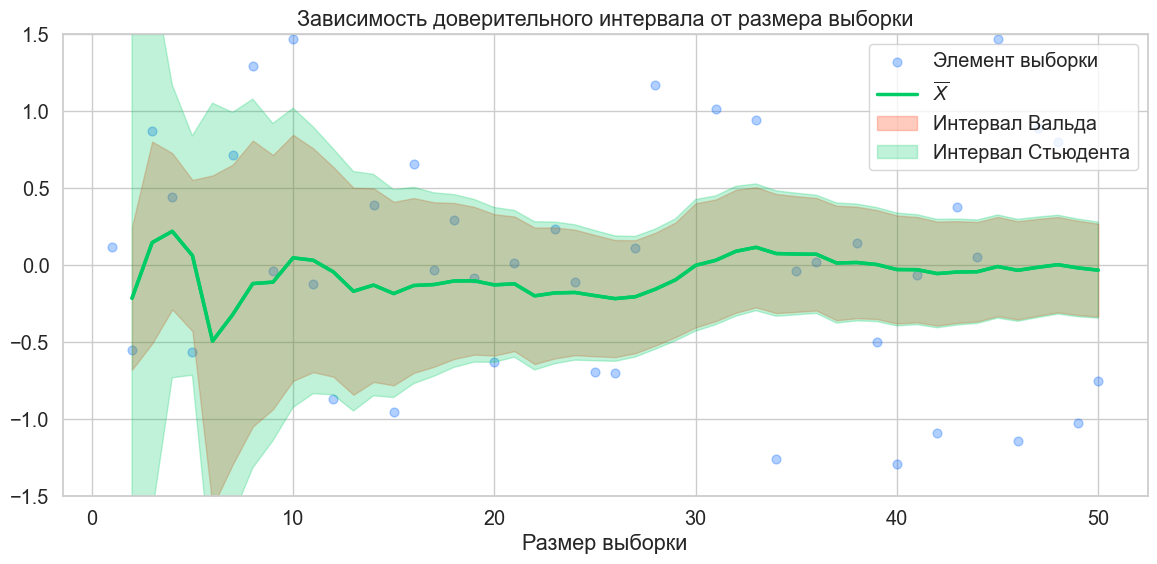

In [24]:
plt.figure(figsize=(14, 6))

draw_confidence_interval(
    left_wald,
    right_wald,
    mean,
    sample,
    ylim=(None, None),
    color_estimation="#00CC66",
    color_interval="#FF3300",
    label_estimation="$\\overline{X}$",
    label_interval="Интервал Вальда",
)

draw_confidence_interval(
    left_student,
    right_student,
    mean,
    ylim=(-1.5, 1.5),
    color_estimation="#00CC66",
    color_interval="#00CC66",
    label_interval="Интервал Стьюдента",
)

Оценим также долю покрытия параметра

In [25]:
def get_coverage_rate(left, right, theta):
    """
    Вычисляет долю покрытия параметра доверительным интервалом.
    :param left, right: Массивы левых и правых границ доверительных интервалов
    :param theta: Значение параметра
    """

    return np.mean((left <= theta) & (theta <= right), axis=0)

Чтобы с большой надежностью оценить долю покрытия параметра и тем самым сделать надежные выводы при сравнении интервалов Стьюдента и Вальда необходимо провести достаточно большое количество семплирований. 

**Оценка доли покрытия**
- Выполним $10^5$ независимых семплирований
- Для каждого семплирования построим оба типа доверительных интервалов для всех размеров выборок $n$ от 2 до $N$
- По всем семплированиям оценим долю покрытия истинного параметра в зависимости от $n$.

In [26]:
n_samples = 100_000  # Количество выборок
param_value = 0  # Истинное значение параметра

# Генерируем все выборки
samples = np.random.normal(size=(n_samples, max_sample_size), loc=param_value)

# Считаем интервалы Вальда и оцениваем долю покрытия
left_wald, right_wald, mean = calculate_sequential_intervals(
    samples,
    partial(calculate_interval, estimate_type="wald"),
    alpha=alpha,
)
coverage_rate_wald = get_coverage_rate(left_wald, right_wald, param_value)

# Считаем интервалы Стьюдента и оцениваем долю покрытия
left_student, right_student, mean = calculate_sequential_intervals(
    samples,
    partial(calculate_interval, estimate_type="student"),
    alpha=alpha,
)
coverage_rate_student = get_coverage_rate(left_student, right_student, param_value)

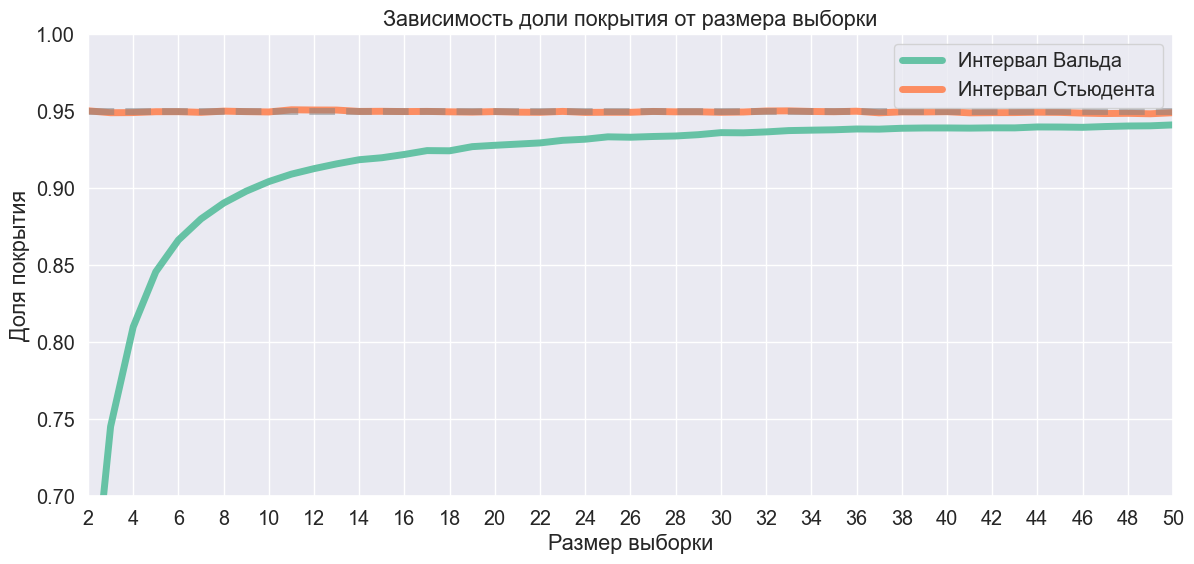

In [27]:
sample_size_grid = np.arange(max_sample_size) + 1

with sns.axes_style("darkgrid"):
    plt.figure(figsize=(14, 6))

    plt.plot(sample_size_grid[1:], coverage_rate_wald[1:], lw=5, label="Интервал Вальда")
    plt.plot(sample_size_grid[1:], coverage_rate_student[1:], lw=5, label="Интервал Стьюдента")
    plt.hlines(alpha, 2, max_sample_size, lw=5, color="gray", linestyles="--", alpha=0.5)
    plt.ylim((0.7, 1.0))
    plt.xlim((2, max_sample_size))
    plt.xticks(np.arange(2, max_sample_size + 1, 2))
    plt.legend()
    plt.xlabel("Размер выборки")
    plt.ylabel("Доля покрытия")
    plt.title("Зависимость доли покрытия от размера выборки")

Мы получили, что при малых размерах выборки интервал Вальда работает плохо. Например, для $n=10$ он покрывает неизвестный истинный параметр лишь в 90% случаев вместо заявленных 95%. Однако с ростом объема данных его качество улучшается.

В отличие от него, интервал Стьюдента является точным и сохраняет корректный уровень доверия при любом размере выборки.

Наконец, сравним доверительный интервал Стьюдента с аналогичным предсказательным интервалом

In [28]:
max_sample_size = 200
sample = np.random.normal(size=max_sample_size)  # выборка
alpha = 0.95  # уровень доверия

left_pred, right_pred, mean = calculate_sequential_intervals(
    sample,
    partial(calculate_interval, estimate_type="student", interval_type="predictive"),
    alpha=alpha,
)

left_conf, right_conf, mean = calculate_sequential_intervals(
    sample,
    partial(calculate_interval, estimate_type="student"),
    alpha=alpha,
)

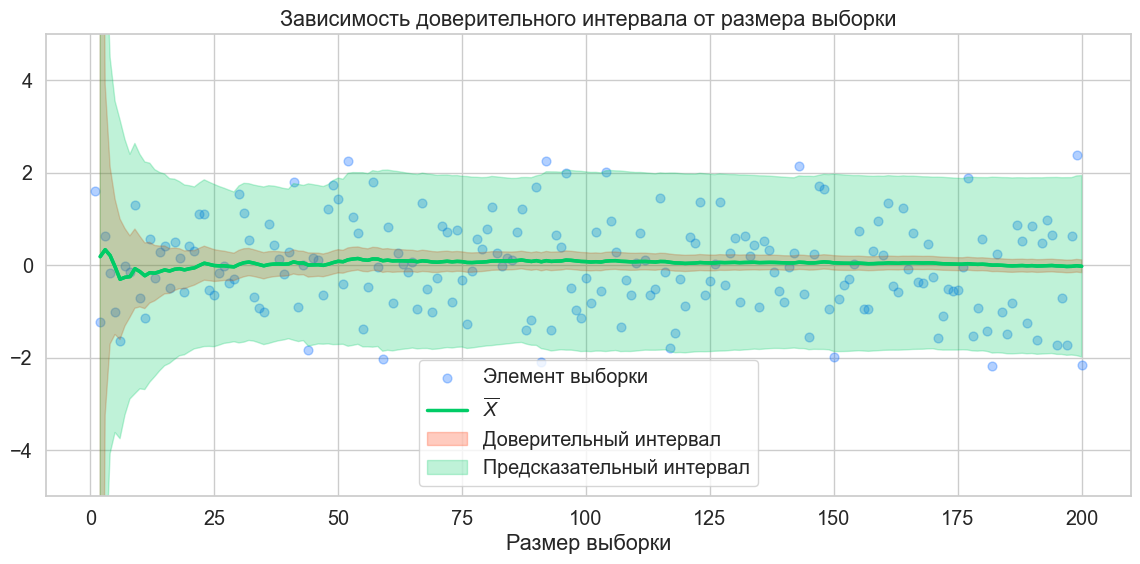

In [29]:
plt.figure(figsize=(14, 6))

draw_confidence_interval(
    left_conf,
    right_conf,
    mean,
    sample,
    ylim=(None, None),
    color_estimation="#00CC66",
    color_interval="#FF3300",
    label_estimation="$\\overline{X}$",
    label_interval="Доверительный интервал",
)

draw_confidence_interval(
    left_pred,
    right_pred,
    mean,
    ylim=(-5, 5),
    color_estimation="#00CC66",
    color_interval="#00CC66",
    label_interval="Предсказательный интервал",
)

Здесь мы видим, что с ростом размера выборки длина доверительного интервала стремится к нулю, отражая всё более точную оценку параметра. В то же время длина предсказательного интервала стабилизируется, приближаясь к естественному разбросу данных, поскольку всегда сохраняется случайная ошибка предсказания.

<div style="box-sizing:border-box;max-width:100%;margin-top:42px;padding:18px 0 4px;border-top:1px solid rgba(127, 127, 127, 0.28);color:inherit;font-size:0.9em;line-height:1.5;"><img src="https://thetahat.ru/images/logo_thetahat.png" alt="ThetaHat" style="display:block!important;width:34px!important;max-width:34px!important;height:auto!important;margin:0 0 9px 0!important;padding:0!important;">© 2026 команда <a href="https://thetahat.ru/" style="color:inherit;font-weight:750;text-decoration:underline;text-decoration-color:#F13A3F;text-underline-offset:3px;">ThetaHat</a> для курса ML-1 ШАД</div>